In [2]:
import numpy as np

# ---------------------------------------------------------
# 1. Synthetic Traffic Data Generator (14 space x 350 time)
# ---------------------------------------------------------
def make_traffic_grid(H=14, W=350, wave_speed=0.18, seed=42, phase_drift=True):
    """
    Generates a synthetic spatiotemporal velocity grid (0 to 100 km/h)
    with backward-propagating diagonal stop-and-go waves.
    """
    rng = np.random.default_rng(seed)
    y = np.arange(H)[:, None]  # Space (0..13)
    t = np.arange(W)[None, :]  # Time (0..349)

    # Base free-flow velocity (~75 km/h)
    grid = np.full((H, W), 75.0)

    # Add 6 quasi-periodic backward-propagating jam waves
    # In your plot, jams move from high y to low y as t increases -> (y + speed * t)
    num_waves = 6
    base_times = np.linspace(20, W - 20, num_waves)
    if phase_drift:
        # Randomize exact arrival times (like a different day of traffic)
        arrival_times = base_times + rng.uniform(-25, 25, size=num_waves)
    else:
        arrival_times = base_times

    for t0 in arrival_times:
        # Diagonal jam center: t_center(y) shifts earlier for higher y
        dist = (t - t0) + (y / wave_speed)
        jam_width = rng.uniform(8.0, 14.0)
        jam_depth = rng.uniform(55.0, 70.0)
        grid -= jam_depth * np.exp(-0.5 * (dist / jam_width) ** 2)

    # Add realistic measurement noise and clip to [0, 100] km/h
    grid += rng.normal(0, 4.0, size=(H, W))
    return np.clip(grid, 0, 100)


# ---------------------------------------------------------
# 2. Metric A: 2-D Power Spectrum (Log-PSD) Distance
# ---------------------------------------------------------
def psd_2d_distance(img1, img2):
    """
    Computes RMSE between the 2-D log power spectra of two images.
    Lower = more similar wave speeds, spacings, and intensities (shift-invariant).
    """
    H, W = img1.shape
    win = np.outer(np.hanning(H), np.hanning(W))

    def log_psd(img):
        centered = img - np.mean(img)
        F = np.fft.fft2(centered * win)
        return np.log1p(np.abs(F) ** 2)

    p1, p2 = log_psd(img1), log_psd(img2)
    return np.sqrt(np.mean((p1 - p2) ** 2))


# ---------------------------------------------------------
# 3. Metric B: 2-D Cross-Spectral Density / Coherence
# ---------------------------------------------------------
def csd_2d_coherence(img1, img2, win_t=80, step_t=20):
    """
    Computes power-weighted 2-D Magnitude-Squared Coherence using Welch's method
    (sliding overlapping windows along the time axis).
    Range: 0 (unsynchronized) to 1 (phase-locked waves).
    """
    H, W = img1.shape
    win = np.outer(np.hanning(H), np.hanning(win_t))

    S11 = np.zeros((H, win_t), dtype=np.float64)
    S22 = np.zeros((H, win_t), dtype=np.float64)
    S12 = np.zeros((H, win_t), dtype=np.complex128)

    n_windows = 0
    for start in range(0, W - win_t + 1, step_t):
        seg1 = img1[:, start : start + win_t]
        seg2 = img2[:, start : start + win_t]

        F1 = np.fft.fft2((seg1 - np.mean(seg1)) * win)
        F2 = np.fft.fft2((seg2 - np.mean(seg2)) * win)

        S11 += np.abs(F1) ** 2
        S22 += np.abs(F2) ** 2
        S12 += F1 * np.conj(F2)
        n_windows += 1

    # Magnitude-squared coherence per (k, omega) frequency bin
    coherence_map = (np.abs(S12) ** 2) / (S11 * S22 + 1e-12)

    # Weight by total spectral power so dominant traffic waves drive the score
    # rather than high-frequency background noise
    weights = S11 + S22
    weighted_coherence = np.sum(coherence_map * weights) / np.sum(weights)
    return weighted_coherence


In [3]:
# ---------------------------------------------------------
# 4. Run Comparison Across 4 Scenarios
# ---------------------------------------------------------
gt = make_traffic_grid(wave_speed=0.18, seed=1)

# Scenario 1: Exact same waves, just lagging by a constant 15 time steps
shifted = np.roll(gt, shift=15, axis=1)

# Scenario 2: "Different day" — same wave physics/speed, different jam timing
diff_day = make_traffic_grid(wave_speed=0.18, seed=99)

# Scenario 3: Different wave physics — much faster/steeper shockwaves
diff_physics = make_traffic_grid(wave_speed=0.45, seed=2)

# Scenario 4: Pure random noise with the same mean and std
rng = np.random.default_rng(0)
noise = np.clip(rng.normal(np.mean(gt), np.std(gt), size=gt.shape), 0, 100)

scenarios = [
    ("Ground Truth vs. Itself", gt),
    ("Constant 15-step Time Lag", shifted),
    ("Different Day (Same Physics)", diff_day),
    ("Different Wave Speed (0.45)", diff_physics),
    ("Unstructured Random Noise", noise),
]

print(f"{'Scenario':<30} | {'2D Log-PSD Dist (↓)':<20} | {'2D CSD Coherence (↑)':<20}")
print("-" * 76)
for name, candidate in scenarios:
    d_psd = psd_2d_distance(gt, candidate)
    coh = csd_2d_coherence(gt, candidate)
    print(f"{name:<30} | {d_psd:<20.3f} | {coh:<20.3f}")

Scenario                       | 2D Log-PSD Dist (↓)  | 2D CSD Coherence (↑)
----------------------------------------------------------------------------
Ground Truth vs. Itself        | 0.000                | 1.000               
Constant 15-step Time Lag      | 0.457                | 0.867               
Different Day (Same Physics)   | 1.776                | 0.160               
Different Wave Speed (0.45)    | 1.847                | 0.486               
Unstructured Random Noise      | 4.095                | 0.111               


Matplotlib is building the font cache; this may take a moment.


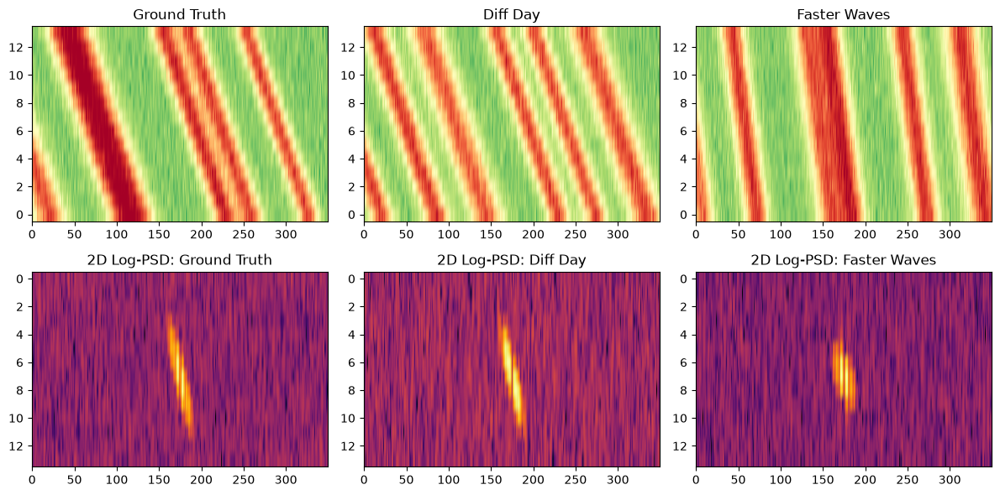

In [4]:
import matplotlib.pyplot as plt

def plot_spectrum(ax, img, title):
    H, W = img.shape
    win = np.outer(np.hanning(H), np.hanning(W))
    F = np.fft.fftshift(np.fft.fft2((img - np.mean(img)) * win))
    ax.imshow(np.log1p(np.abs(F) ** 2), aspect="auto", cmap="inferno")
    ax.set_title(title)

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for i, (name, arr) in enumerate([("Ground Truth", gt), ("Diff Day", diff_day), ("Faster Waves", diff_physics)]):
    axes[0, i].imshow(arr, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100, origin="lower")
    axes[0, i].set_title(name)
    plot_spectrum(axes[1, i], arr, f"2D Log-PSD: {name}")

plt.tight_layout()
plt.show()

Candidate A (Realistic, Unsynced) -> PSD Dist: 1.776 | CSD Coh: 0.160
Candidate B (Washed-Out, Synced)  -> PSD Dist: 2.616 | CSD Coh: 0.974


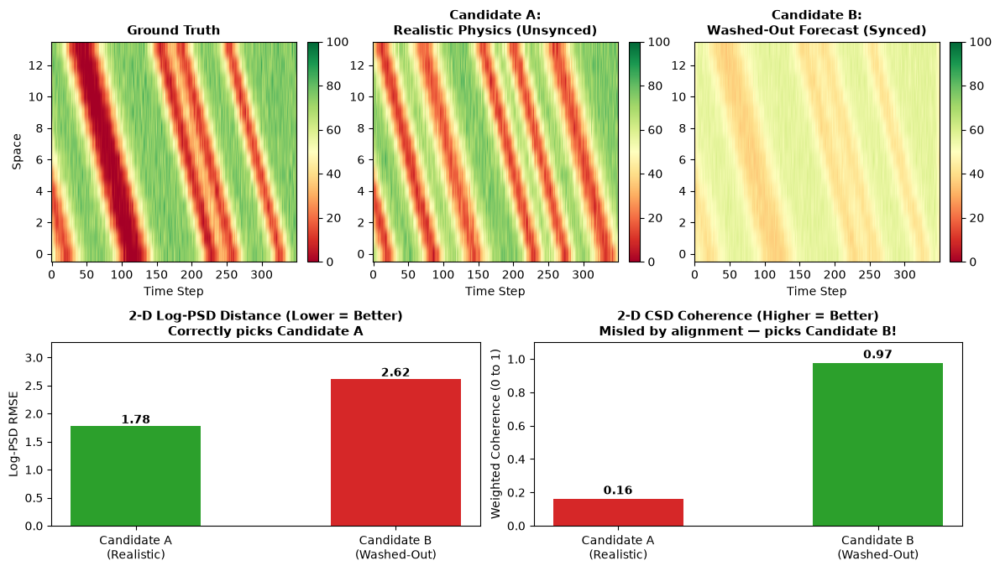

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ---------------------------------------------------------
# 1. Synthetic Traffic Generator & Metrics
# ---------------------------------------------------------
def make_traffic_grid(H=14, W=350, wave_speed=0.18, seed=42):
    rng = np.random.default_rng(seed)
    y = np.arange(H)[:, None]
    t = np.arange(W)[None, :]
    grid = np.full((H, W), 75.0)

    num_waves = 6
    arrival_times = np.linspace(20, W - 20, num_waves) + rng.uniform(-25, 25, size=num_waves)
    for t0 in arrival_times:
        dist = (t - t0) + (y / wave_speed)
        jam_width = rng.uniform(8.0, 14.0)
        jam_depth = rng.uniform(55.0, 70.0)
        grid -= jam_depth * np.exp(-0.5 * (dist / jam_width) ** 2)

    grid += rng.normal(0, 4.0, size=(H, W))
    return np.clip(grid, 0, 100)


def psd_2d_distance(img1, img2):
    H, W = img1.shape
    win = np.outer(np.hanning(H), np.hanning(W))
    def log_psd(img):
        F = np.fft.fft2((img - np.mean(img)) * win)
        return np.log1p(np.abs(F) ** 2)
    return np.sqrt(np.mean((log_psd(img1) - log_psd(img2)) ** 2))


def csd_2d_coherence(img1, img2, win_t=80, step_t=20):
    H, W = img1.shape
    win = np.outer(np.hanning(H), np.hanning(win_t))
    S11 = np.zeros((H, win_t))
    S22 = np.zeros((H, win_t))
    S12 = np.zeros((H, win_t), dtype=np.complex128)

    for start in range(0, W - win_t + 1, step_t):
        s1 = img1[:, start : start + win_t]
        s2 = img2[:, start : start + win_t]
        F1 = np.fft.fft2((s1 - np.mean(s1)) * win)
        F2 = np.fft.fft2((s2 - np.mean(s2)) * win)
        S11 += np.abs(F1) ** 2
        S22 += np.abs(F2) ** 2
        S12 += F1 * np.conj(F2)

    coh_map = (np.abs(S12) ** 2) / (S11 * S22 + 1e-12)
    weights = S11 + S22
    return np.sum(coh_map * weights) / np.sum(weights)


# ---------------------------------------------------------
# 2. Build the Showdown Cases
# ---------------------------------------------------------
gt = make_traffic_grid(wave_speed=0.18, seed=1)

# Candidate A: Realistic physics, same wave speed & jam depth, different timing
cand_a = make_traffic_grid(wave_speed=0.18, seed=99)

# Candidate B: Time-aligned, but washed-out (25% amplitude) & blurred in time
kernel = np.ones(11) / 11.0
blurred = np.apply_along_axis(lambda row: np.convolve(row, kernel, mode="same"), 1, gt)
rng = np.random.default_rng(7)
cand_b = np.mean(gt) + 0.25 * (blurred - np.mean(gt)) + rng.normal(0, 1.5, size=gt.shape)
cand_b = np.clip(cand_b, 0, 100)

# Compute scores
psd_a, psd_b = psd_2d_distance(gt, cand_a), psd_2d_distance(gt, cand_b)
csd_a, csd_b = csd_2d_coherence(gt, cand_a), csd_2d_coherence(gt, cand_b)

print(f"Candidate A (Realistic, Unsynced) -> PSD Dist: {psd_a:.3f} | CSD Coh: {csd_a:.3f}")
print(f"Candidate B (Washed-Out, Synced)  -> PSD Dist: {psd_b:.3f} | CSD Coh: {csd_b:.3f}")

# ---------------------------------------------------------
# 3. Visualize Heatmaps + Score Divergence
# ---------------------------------------------------------
fig = plt.figure(figsize=(14, 7.5))
gs = gridspec.GridSpec(2, 6, height_ratios=[1.2, 1], hspace=0.4, wspace=0.5)

# Top Row: 3 Traffic Heatmaps
cases = [
    ("Ground Truth", gt),
    ("Candidate A:\nRealistic Physics (Unsynced)", cand_a),
    ("Candidate B:\nWashed-Out Forecast (Synced)", cand_b),
]
for i, (title, arr) in enumerate(cases):
    ax = fig.add_subplot(gs[0, i * 2 : (i + 1) * 2])
    im = ax.imshow(arr, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100, origin="lower")
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Time Step")
    if i == 0:
        ax.set_ylabel("Space")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# Bottom Left: 2-D Log-PSD Distance (Lower is Better)
ax_psd = fig.add_subplot(gs[1, 0:3])
bars1 = ax_psd.bar(["Candidate A\n(Realistic)", "Candidate B\n(Washed-Out)"], [psd_a, psd_b], color=["#2ca02c", "#d62728"], width=0.5)
ax_psd.set_title("2-D Log-PSD Distance (Lower = Better)\nCorrectly picks Candidate A", fontsize=11, fontweight="bold")
ax_psd.set_ylabel("Log-PSD RMSE")
ax_psd.set_ylim(0, max(psd_a, psd_b) * 1.25)
for bar in bars1:
    ax_psd.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05, f"{bar.get_height():.2f}", ha="center", fontweight="bold")

# Bottom Right: 2-D CSD Coherence (Higher is Better)
ax_csd = fig.add_subplot(gs[1, 3:6])
bars2 = ax_csd.bar(["Candidate A\n(Realistic)", "Candidate B\n(Washed-Out)"], [csd_a, csd_b], color=["#d62728", "#2ca02c"], width=0.5)
ax_csd.set_title("2-D CSD Coherence (Higher = Better)\nMisled by alignment — picks Candidate B!", fontsize=11, fontweight="bold")
ax_csd.set_ylabel("Weighted Coherence (0 to 1)")
ax_csd.set_ylim(0, 1.1)
for bar in bars2:
    ax_csd.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.03, f"{bar.get_height():.2f}", ha="center", fontweight="bold")

plt.show()

Candidate A (Realistic, Unsynced) -> PSD Dist: 1.776 | CSD Dist: 0.840
Candidate B (Washed-Out, Synced)  -> PSD Dist: 2.616 | CSD Dist: 0.026


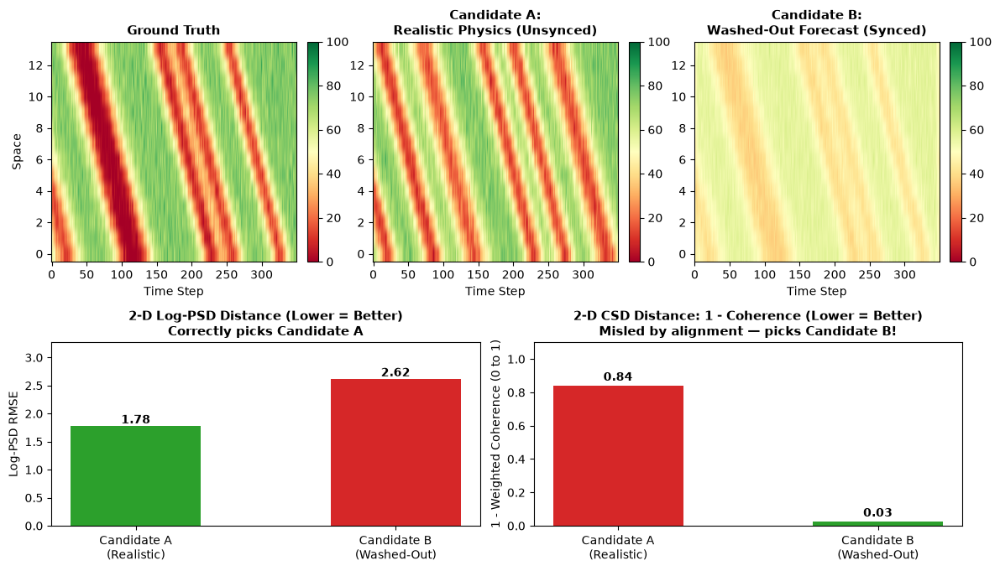

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ---------------------------------------------------------
# 1. Synthetic Traffic Generator & Metrics (Both: Lower = Better)
# ---------------------------------------------------------
def make_traffic_grid(H=14, W=350, wave_speed=0.18, seed=42):
    rng = np.random.default_rng(seed)
    y = np.arange(H)[:, None]
    t = np.arange(W)[None, :]
    grid = np.full((H, W), 75.0)

    num_waves = 6
    arrival_times = np.linspace(20, W - 20, num_waves) + rng.uniform(-25, 25, size=num_waves)
    for t0 in arrival_times:
        dist = (t - t0) + (y / wave_speed)
        jam_width = rng.uniform(8.0, 14.0)
        jam_depth = rng.uniform(55.0, 70.0)
        grid -= jam_depth * np.exp(-0.5 * (dist / jam_width) ** 2)

    grid += rng.normal(0, 4.0, size=(H, W))
    return np.clip(grid, 0, 100)


def psd_2d_distance(img1, img2):
    """2-D Log-PSD RMSE. Lower = more similar wave physics."""
    H, W = img1.shape
    win = np.outer(np.hanning(H), np.hanning(W))
    def log_psd(img):
        F = np.fft.fft2((img - np.mean(img)) * win)
        return np.log1p(np.abs(F) ** 2)
    return np.sqrt(np.mean((log_psd(img1) - log_psd(img2)) ** 2))


def csd_2d_distance(img1, img2, win_t=80, step_t=20):
    """1 - Weighted 2-D Coherence (range 0 to 1). Lower = more phase-locked."""
    H, W = img1.shape
    win = np.outer(np.hanning(H), np.hanning(win_t))
    S11 = np.zeros((H, win_t))
    S22 = np.zeros((H, win_t))
    S12 = np.zeros((H, win_t), dtype=np.complex128)

    for start in range(0, W - win_t + 1, step_t):
        s1 = img1[:, start : start + win_t]
        s2 = img2[:, start : start + win_t]
        F1 = np.fft.fft2((s1 - np.mean(s1)) * win)
        F2 = np.fft.fft2((s2 - np.mean(s2)) * win)
        S11 += np.abs(F1) ** 2
        S22 += np.abs(F2) ** 2
        S12 += F1 * np.conj(F2)

    coh_map = (np.abs(S12) ** 2) / (S11 * S22 + 1e-12)
    weights = S11 + S22
    weighted_coherence = np.sum(coh_map * weights) / np.sum(weights)
    return 1.0 - weighted_coherence


# ---------------------------------------------------------
# 2. Build the Showdown Cases
# ---------------------------------------------------------
gt = make_traffic_grid(wave_speed=0.18, seed=1)

# Candidate A: Realistic physics, same wave speed & jam depth, different timing
cand_a = make_traffic_grid(wave_speed=0.18, seed=99)

# Candidate B: Time-aligned, but washed-out (25% amplitude) & blurred in time
kernel = np.ones(11) / 11.0
blurred = np.apply_along_axis(lambda row: np.convolve(row, kernel, mode="same"), 1, gt)
rng = np.random.default_rng(7)
cand_b = np.mean(gt) + 0.25 * (blurred - np.mean(gt)) + rng.normal(0, 1.5, size=gt.shape)
cand_b = np.clip(cand_b, 0, 100)

# Compute distances (Lower = Better for both)
psd_a, psd_b = psd_2d_distance(gt, cand_a), psd_2d_distance(gt, cand_b)
csd_a, csd_b = csd_2d_distance(gt, cand_a), csd_2d_distance(gt, cand_b)

print(f"Candidate A (Realistic, Unsynced) -> PSD Dist: {psd_a:.3f} | CSD Dist: {csd_a:.3f}")
print(f"Candidate B (Washed-Out, Synced)  -> PSD Dist: {psd_b:.3f} | CSD Dist: {csd_b:.3f}")

# ---------------------------------------------------------
# 3. Visualize Heatmaps + Score Divergence (Both: Lower = Better)
# ---------------------------------------------------------
fig = plt.figure(figsize=(14, 7.5))
gs = gridspec.GridSpec(2, 6, height_ratios=[1.2, 1], hspace=0.4, wspace=0.5)

# Top Row: 3 Traffic Heatmaps
cases = [
    ("Ground Truth", gt),
    ("Candidate A:\nRealistic Physics (Unsynced)", cand_a),
    ("Candidate B:\nWashed-Out Forecast (Synced)", cand_b),
]
for i, (title, arr) in enumerate(cases):
    ax = fig.add_subplot(gs[0, i * 2 : (i + 1) * 2])
    im = ax.imshow(arr, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100, origin="lower")
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Time Step")
    if i == 0:
        ax.set_ylabel("Space")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# Bottom Left: 2-D Log-PSD Distance (Lower = Better)
ax_psd = fig.add_subplot(gs[1, 0:3])
bars1 = ax_psd.bar(["Candidate A\n(Realistic)", "Candidate B\n(Washed-Out)"], [psd_a, psd_b], color=["#2ca02c", "#d62728"], width=0.5)
ax_psd.set_title("2-D Log-PSD Distance (Lower = Better)\nCorrectly picks Candidate A", fontsize=11, fontweight="bold")
ax_psd.set_ylabel("Log-PSD RMSE")
ax_psd.set_ylim(0, max(psd_a, psd_b) * 1.25)
for bar in bars1:
    ax_psd.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05, f"{bar.get_height():.2f}", ha="center", fontweight="bold")

# Bottom Right: 2-D CSD Distance (Lower = Better)
ax_csd = fig.add_subplot(gs[1, 3:6])
bars2 = ax_csd.bar(["Candidate A\n(Realistic)", "Candidate B\n(Washed-Out)"], [csd_a, csd_b], color=["#d62728", "#2ca02c"], width=0.5)
ax_csd.set_title("2-D CSD Distance: 1 - Coherence (Lower = Better)\nMisled by alignment — picks Candidate B!", fontsize=11, fontweight="bold")
ax_csd.set_ylabel("1 - Weighted Coherence (0 to 1)")
ax_csd.set_ylim(0, 1.1)
for bar in bars2:
    ax_csd.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.03, f"{bar.get_height():.2f}", ha="center", fontweight="bold")

plt.show()

Variant                | 2D Log-PSD Dist (↓)  | 2D CSD Dist (↓) 
----------------------------------------------------------------
Shifted Start Point    | 0.176                | 0.022           
Faster Wave Speed      | 0.199                | 0.873           
Slower Wave Speed      | 4.931                | 0.838           
More Waves (3)         | 0.229                | 0.667           
Fewer Waves (1)        | 0.346                | 0.949           


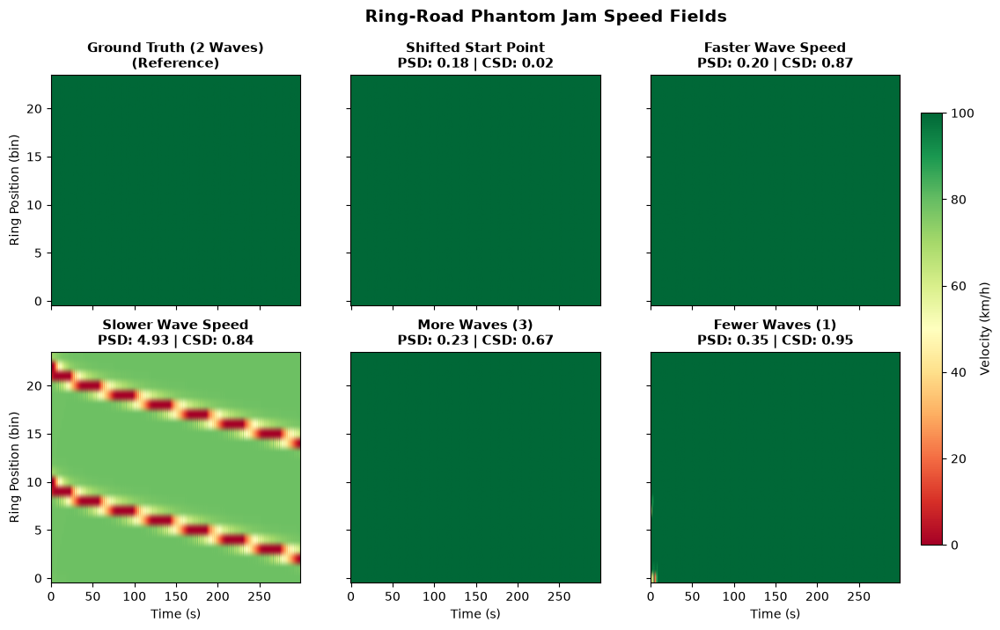

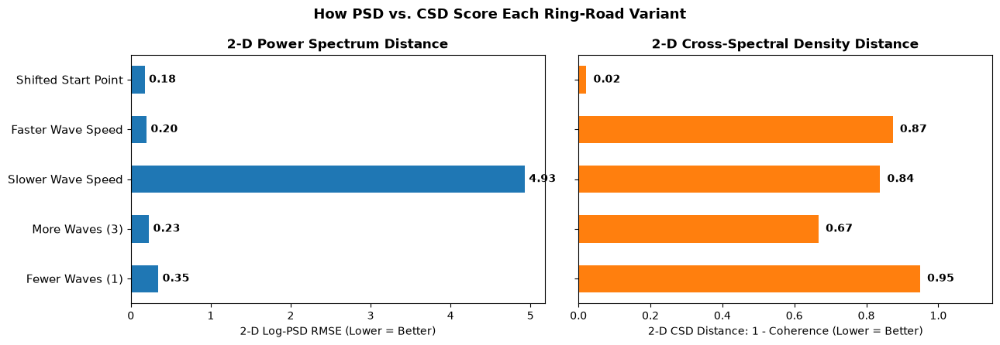

Variant                | Speed Range (km/h) | 2D Log-PSD (↓) | 2D CSD (↓)
--------------------------------------------------------------------------
Ground Truth           |   0.3 –  85.7      | 0.000          | 0.000     
Shifted Start Point    |   0.3 –  85.7      | 0.829          | 0.000     
Faster Wave Speed      |   0.4 – 114.3      | 2.622          | 0.669     
Slower Wave Speed      |   0.2 –  57.1      | 2.435          | 0.483     
More Waves (3)         |   0.3 –  85.7      | 5.259          | 0.122     
Fewer Waves (1)        |   0.3 –  85.7      | 6.033          | 0.455     


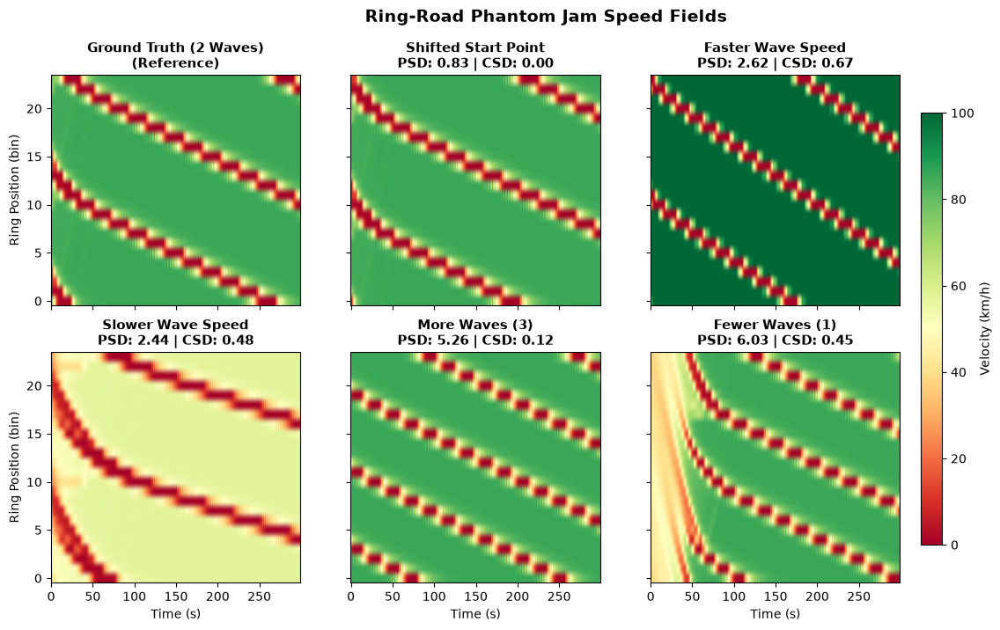

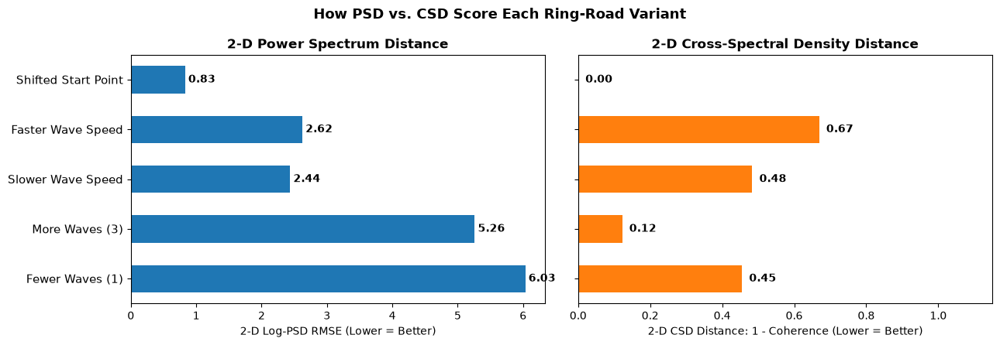

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Ring-Road Phantom Jam Simulator (Collision-Safe OVM)
# ---------------------------------------------------------
def simulate_ring_road(
    L=1200.0,        # Ring circumference (meters)
    N=60,            # Number of vehicles (equilibrium headway h* = 20 m)
    v_max=24.0,      # Max speed (m/s)
    width=6.5,       # Transition width of optimal velocity curve
    alpha=None,      # Driver sensitivity (auto-tuned to 0.65 * V'(h*) if None)
    h_c=20.0,        # Critical headway (meters)
    n_waves=2,       # Number of jam waves seeded around the ring
    phase_shift=0.0, # Starting angular offset of the jam (radians)
    dt=0.02,         # Smaller timestep for numerical stability
    burn_in=80.0,    # Time (s) to let phantom jams develop
    duration=300.0,  # Recorded window (s)
    n_space=24,      # Spatial grid resolution
):
    # Keep alpha / V'(h*) = 0.65 so jams always form without car collisions
    if alpha is None:
        v_prime = v_max / (2.0 * width)
        alpha = 0.65 * v_prime

    # Initialize cars uniformly + small sinusoidal perturbation to seed n_waves
    i = np.arange(N)
    x = (i * (L / N) + 1.5 * np.sin(2 * np.pi * n_waves * i / N + phase_shift)) % L
    v = np.full(N, v_max * 0.5)

    def opt_vel(h):
        return 0.5 * v_max * (np.tanh((h - h_c) / width) + np.tanh(h_c / width))

    y_grid = np.linspace(0, L, n_space, endpoint=False)
    total_steps = int((burn_in + duration) / dt)
    record_every = int(1.0 / dt)  # Record 1 frame per second
    burn_steps = int(burn_in / dt)

    frames = []
    for step in range(total_steps):
        headway = (np.roll(x, -1) - x) % L
        acc = alpha * (opt_vel(headway) - v)

        v = np.clip(v + acc * dt, 0.0, v_max)
        x = (x + v * dt) % L

        if step >= burn_steps and (step - burn_steps) % record_every == 0:
            order = np.argsort(x)
            x_s, v_s = x[order], v[order]
            x_ext = np.concatenate(([x_s[-1] - L], x_s, [x_s[0] + L]))
            v_ext = np.concatenate(([v_s[-1]], v_s, [v_s[0]]))
            speed_kmh = np.interp(y_grid, x_ext, v_ext) * 3.6
            frames.append(speed_kmh)

    return np.array(frames).T  # Shape: (n_space, n_time)


# ---------------------------------------------------------
# 2. Spectral Distance Metrics (Both: Lower = Better)
#    Note: Ring road is periodic in space, so we only window time.
# ---------------------------------------------------------
def psd_2d_distance(img1, img2):
    """2-D Log-PSD RMSE. Captures wave speed, spacing, and jam depth."""
    _, W = img1.shape
    win = np.hanning(W)[None, :]  # Window time only (space is periodic)
    def log_psd(img):
        F = np.fft.fft2((img - np.mean(img)) * win)
        return np.log1p(np.abs(F) ** 2)
    return np.sqrt(np.mean((log_psd(img1) - log_psd(img2)) ** 2))


def csd_2d_distance(img1, img2, win_t=80, step_t=20):
    """1 - Weighted 2-D Coherence (0 to 1). Measures phase-locking."""
    H, W = img1.shape
    win = np.hanning(win_t)[None, :]
    S11 = np.zeros((H, win_t))
    S22 = np.zeros((H, win_t))
    S12 = np.zeros((H, win_t), dtype=np.complex128)

    for start in range(0, W - win_t + 1, step_t):
        s1 = img1[:, start : start + win_t]
        s2 = img2[:, start : start + win_t]
        F1 = np.fft.fft2((s1 - np.mean(s1)) * win)
        F2 = np.fft.fft2((s2 - np.mean(s2)) * win)
        S11 += np.abs(F1) ** 2
        S22 += np.abs(F2) ** 2
        S12 += F1 * np.conj(F2)

    coh_map = (np.abs(S12) ** 2) / (S11 * S22 + 1e-12)
    weights = S11 + S22
    return 1.0 - (np.sum(coh_map * weights) / np.sum(weights))


# ---------------------------------------------------------
# 3. Generate Ground Truth & 5 Variants (All Guaranteed Waves)
# ---------------------------------------------------------
gt = simulate_ring_road(n_waves=2, v_max=24.0, phase_shift=0.0)

variants = {
    "Shifted Start Point": simulate_ring_road(n_waves=2, v_max=24.0, phase_shift=np.pi / 2),
    "Faster Wave Speed":   simulate_ring_road(n_waves=2, v_max=32.0, phase_shift=0.0),
    "Slower Wave Speed":   simulate_ring_road(n_waves=2, v_max=16.0, phase_shift=0.0),
    "More Waves (3)":      simulate_ring_road(n_waves=3, v_max=24.0, phase_shift=0.0),
    "Fewer Waves (1)":     simulate_ring_road(n_waves=1, v_max=24.0, phase_shift=0.0),
}

scores = {}
print(f"{'Variant':<22} | {'Speed Range (km/h)':<18} | {'2D Log-PSD (↓)':<14} | {'2D CSD (↓)':<10}")
print("-" * 74)
print(f"{'Ground Truth':<22} | {gt.min():5.1f} – {gt.max():5.1f}      | {'0.000':<14} | {'0.000':<10}")
for name, grid in variants.items():
    d_psd = psd_2d_distance(gt, grid)
    d_csd = csd_2d_distance(gt, grid)
    scores[name] = (d_psd, d_csd)
    print(f"{name:<22} | {grid.min():5.1f} – {grid.max():5.1f}      | {d_psd:<14.3f} | {d_csd:<10.3f}")


# ---------------------------------------------------------
# 4. Plot 1: Speed Fields (Ground Truth + 5 Variants)
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True, sharey=True)
all_plots = [("Ground Truth (2 Waves)", gt)] + list(variants.items())

for ax, (title, grid) in zip(axes.ravel(), all_plots):
    im = ax.imshow(grid, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100, origin="lower")
    if title in scores:
        d_psd, d_csd = scores[title]
        ax.set_title(f"{title}\nPSD: {d_psd:.2f} | CSD: {d_csd:.2f}", fontsize=10.5, fontweight="bold")
    else:
        ax.set_title(f"{title}\n(Reference)", fontsize=10.5, fontweight="bold")

for ax in axes[1, :]:
    ax.set_xlabel("Time (s)")
for ax in axes[:, 0]:
    ax.set_ylabel("Ring Position (bin)")

fig.colorbar(im, ax=axes.ravel().tolist(), label="Velocity (km/h)", shrink=0.85, pad=0.02)
fig.suptitle("Ring-Road Phantom Jam Speed Fields", fontsize=14, fontweight="bold")
plt.show()


# ---------------------------------------------------------
# 5. Plot 2: Score Comparison (Both: Lower = Better)
# ---------------------------------------------------------
names = list(scores.keys())
psd_vals = [scores[n][0] for n in names]
csd_vals = [scores[n][1] for n in names]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
y_pos = np.arange(len(names))

ax1.barh(y_pos, psd_vals, color="#1f77b4", height=0.55)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(names, fontsize=10.5)
ax1.invert_yaxis()
ax1.set_xlabel("2-D Log-PSD RMSE (Lower = Better)")
ax1.set_title("2-D Power Spectrum Distance", fontweight="bold")
for i, v in enumerate(psd_vals):
    ax1.text(v + 0.05, i, f"{v:.2f}", va="center", fontweight="bold")

ax2.barh(y_pos, csd_vals, color="#ff7f0e", height=0.55)
ax2.set_xlabel("2-D CSD Distance: 1 - Coherence (Lower = Better)")
ax2.set_title("2-D Cross-Spectral Density Distance", fontweight="bold")
ax2.set_xlim(0, 1.15)
for i, v in enumerate(csd_vals):
    ax2.text(v + 0.02, i, f"{v:.2f}", va="center", fontweight="bold")

fig.suptitle("How PSD vs. CSD Score Each Ring-Road Variant", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

Saved animation to ring_road_jams.gif


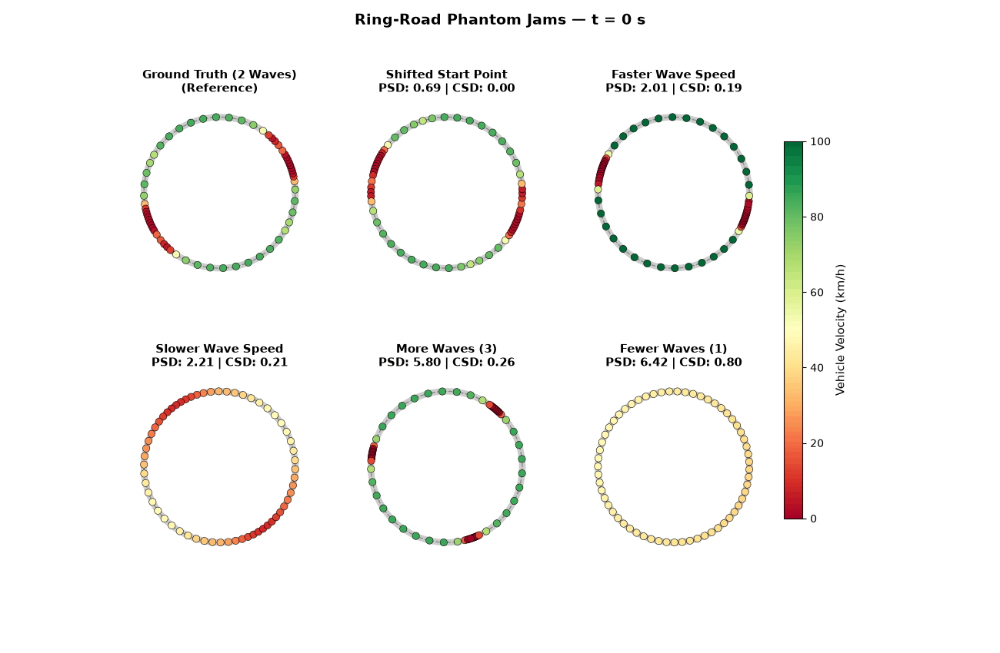

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

# ---------------------------------------------------------
# 1. Ring-Road Simulator (Returns Speed Field + Car Trajectories)
# ---------------------------------------------------------
def simulate_ring_road(
    L=1200.0,
    N=60,
    v_max=24.0,
    width=6.5,
    alpha=None,
    h_c=20.0,
    n_waves=2,
    phase_shift=0.0,
    dt=0.02,
    burn_in=80.0,
    duration=150.0,  # 150s is plenty for a crisp, fast-rendering GIF
    n_space=24,
):
    if alpha is None:
        v_prime = v_max / (2.0 * width)
        alpha = 0.65 * v_prime

    i = np.arange(N)
    x = (i * (L / N) + 1.5 * np.sin(2 * np.pi * n_waves * i / N + phase_shift)) % L
    v = np.full(N, v_max * 0.5)

    def opt_vel(h):
        return 0.5 * v_max * (np.tanh((h - h_c) / width) + np.tanh(h_c / width))

    y_grid = np.linspace(0, L, n_space, endpoint=False)
    total_steps = int((burn_in + duration) / dt)
    record_every = int(1.0 / dt)  # 1 frame per simulated second
    burn_steps = int(burn_in / dt)

    speed_frames, traj_x, traj_v = [], [], []
    for step in range(total_steps):
        headway = (np.roll(x, -1) - x) % L
        acc = alpha * (opt_vel(headway) - v)

        v = np.clip(v + acc * dt, 0.0, v_max)
        x = (x + v * dt) % L

        if step >= burn_steps and (step - burn_steps) % record_every == 0:
            traj_x.append(x.copy())
            traj_v.append(v.copy() * 3.6)  # km/h

            order = np.argsort(x)
            x_s, v_s = x[order], v[order]
            x_ext = np.concatenate(([x_s[-1] - L], x_s, [x_s[0] + L]))
            v_ext = np.concatenate(([v_s[-1]], v_s, [v_s[0]]))
            speed_frames.append(np.interp(y_grid, x_ext, v_ext) * 3.6)

    return np.array(speed_frames).T, np.array(traj_x), np.array(traj_v)


# ---------------------------------------------------------
# 2. Spectral Distance Metrics (Both: Lower = Better)
# ---------------------------------------------------------
def psd_2d_distance(img1, img2):
    _, W = img1.shape
    win = np.hanning(W)[None, :]
    def log_psd(img):
        F = np.fft.fft2((img - np.mean(img)) * win)
        return np.log1p(np.abs(F) ** 2)
    return np.sqrt(np.mean((log_psd(img1) - log_psd(img2)) ** 2))


def csd_2d_distance(img1, img2, win_t=50, step_t=15):
    H, W = img1.shape
    win = np.hanning(win_t)[None, :]
    S11 = np.zeros((H, win_t))
    S22 = np.zeros((H, win_t))
    S12 = np.zeros((H, win_t), dtype=np.complex128)

    for start in range(0, W - win_t + 1, step_t):
        s1 = img1[:, start : start + win_t]
        s2 = img2[:, start : start + win_t]
        F1 = np.fft.fft2((s1 - np.mean(s1)) * win)
        F2 = np.fft.fft2((s2 - np.mean(s2)) * win)
        S11 += np.abs(F1) ** 2
        S22 += np.abs(F2) ** 2
        S12 += F1 * np.conj(F2)

    coh_map = (np.abs(S12) ** 2) / (S11 * S22 + 1e-12)
    weights = S11 + S22
    return 1.0 - (np.sum(coh_map * weights) / np.sum(weights))


# ---------------------------------------------------------
# 3. Run All 6 Simulations
# ---------------------------------------------------------
L = 1200.0
configs = [
    ("Ground Truth (2 Waves)", dict(n_waves=2, v_max=24.0, phase_shift=0.0)),
    ("Shifted Start Point",    dict(n_waves=2, v_max=24.0, phase_shift=np.pi / 2)),
    ("Faster Wave Speed",      dict(n_waves=2, v_max=32.0, phase_shift=0.0)),
    ("Slower Wave Speed",      dict(n_waves=2, v_max=16.0, phase_shift=0.0)),
    ("More Waves (3)",         dict(n_waves=3, v_max=24.0, phase_shift=0.0)),
    ("Fewer Waves (1)",        dict(n_waves=1, v_max=24.0, phase_shift=0.0)),
]

results = []
for name, kwargs in configs:
    grid, tx, tv = simulate_ring_road(L=L, **kwargs)
    results.append((name, grid, tx, tv))

gt_grid = results[0][1]

# ---------------------------------------------------------
# 4. Build 2x3 Animated Ring-Road Visualization
# ---------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))
fig.patch.set_facecolor("white")

ring_theta = np.linspace(0, 2 * np.pi, 200)
scatters = []

for idx, (ax, (name, grid, tx, tv)) in enumerate(zip(axes.ravel(), results)):
    # Draw the circular road track
    ax.plot(np.cos(ring_theta), np.sin(ring_theta), color="#cccccc", lw=6, zorder=1)
    ax.plot(np.cos(ring_theta), np.sin(ring_theta), color="#888888", lw=1, ls="--", zorder=2)

    # Initial car positions & speeds
    theta0 = 2 * np.pi * tx[0] / L
    scat = ax.scatter(
        np.cos(theta0), np.sin(theta0),
        c=tv[0], cmap="RdYlGn", vmin=0, vmax=100,
        s=45, edgecolors="black", linewidths=0.4, zorder=3
    )
    scatters.append(scat)

    # Title with PSD & CSD scores
    if idx == 0:
        ax.set_title(f"{name}\n(Reference)", fontsize=10.5, fontweight="bold")
    else:
        d_psd = psd_2d_distance(gt_grid, grid)
        d_csd = csd_2d_distance(gt_grid, grid)
        ax.set_title(f"{name}\nPSD: {d_psd:.2f} | CSD: {d_csd:.2f}", fontsize=10.5, fontweight="bold")

    ax.set_aspect("equal")
    ax.set_xlim(-1.25, 1.25)
    ax.set_ylim(-1.25, 1.25)
    ax.axis("off")

# Shared colorbar & live timestamp
cbar = fig.colorbar(scatters[0], ax=axes.ravel().tolist(), shrink=0.75, pad=0.02)
cbar.set_label("Vehicle Velocity (km/h)", fontsize=11)
time_text = fig.suptitle("Ring-Road Phantom Jams — t = 0 s", fontsize=14, fontweight="bold")

n_frames = results[0][2].shape[0]

def update(frame):
    for scat, (_, _, tx, tv) in zip(scatters, results):
        theta = 2 * np.pi * tx[frame] / L
        scat.set_offsets(np.column_stack([np.cos(theta), np.sin(theta)]))
        scat.set_array(tv[frame])
    time_text.set_text(f"Ring-Road Phantom Jams — t = {frame} s")
    return scatters + [time_text]

anim = FuncAnimation(fig, update, frames=n_frames, interval=60, blit=False)

# Save as GIF (uses Pillow, no ffmpeg required)
anim.save("ring_road_jams.gif", writer=PillowWriter(fps=15))
print("Saved animation to ring_road_jams.gif")

plt.close(fig)
from IPython.display import Image
Image(filename="ring_road_jams.gif")

Variant                  | Speed Range (km/h) | 2D Log-PSD (↓) | 2D CSD (↓)
----------------------------------------------------------------------------
Ground Truth (2 Waves)   |   0.3 –  85.7      | 0.000          | 0.000     
Shifted Start Point      |   0.3 –  85.7      | 0.685          | 0.000     
Faster Wave Speed        |   0.4 – 114.3      | 2.010          | 0.189     
Slower Wave Speed        |   0.2 –  57.1      | 2.207          | 0.212     
More Waves (3)           |   0.3 –  85.7      | 5.801          | 0.258     
Fewer Waves (1)          |   0.3 –  85.7      | 6.423          | 0.804     


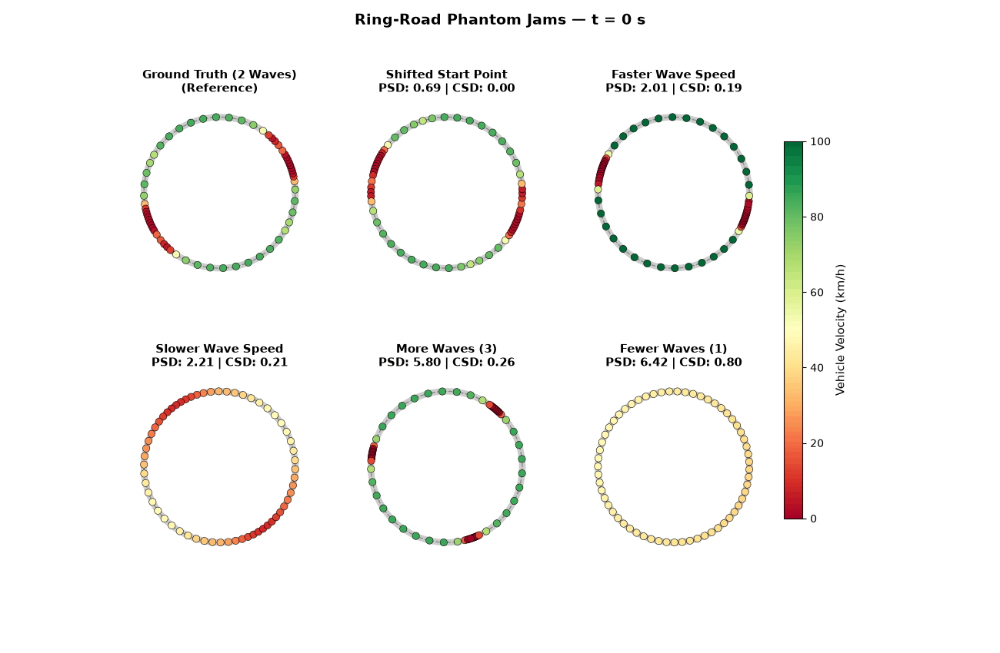

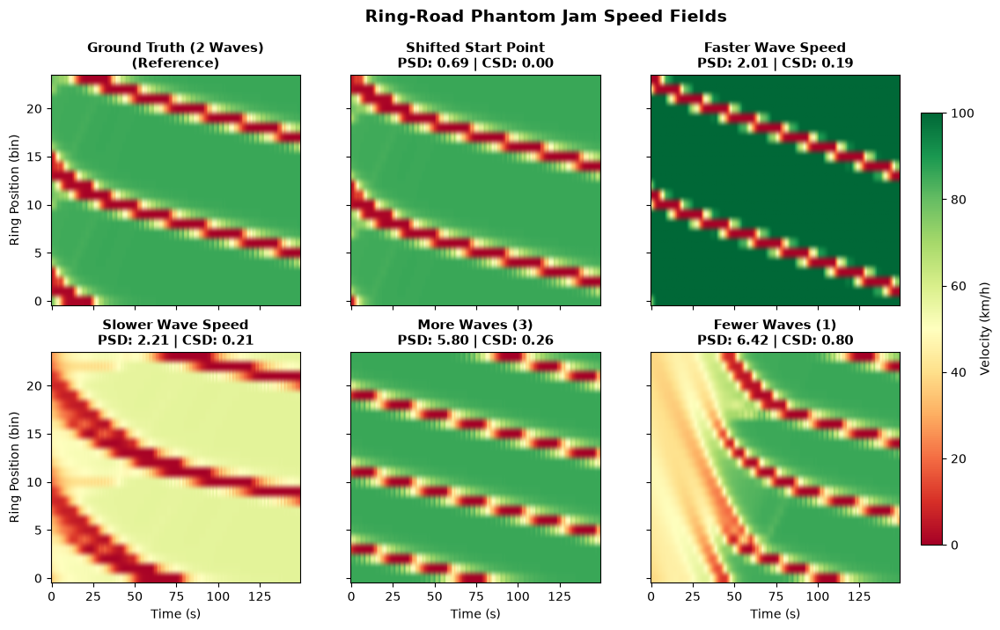

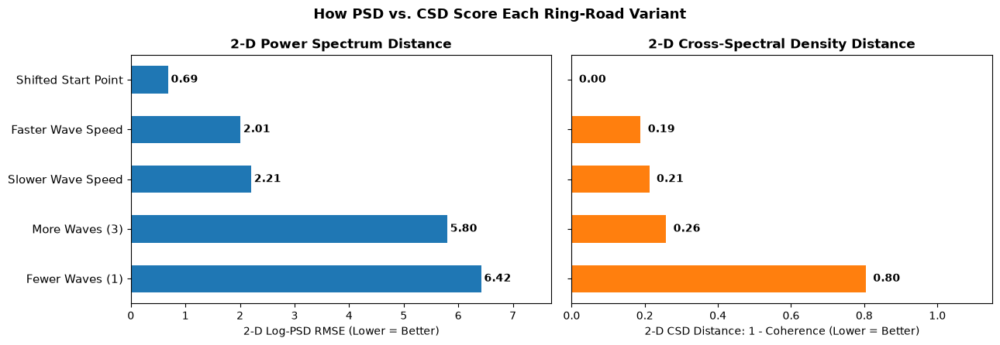

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import display, Image

# ---------------------------------------------------------
# 1. Ring-Road Simulator (Collision-Safe OVM)
# ---------------------------------------------------------
def simulate_ring_road(
    L=1200.0,
    N=60,
    v_max=24.0,
    width=6.5,
    alpha=None,
    h_c=20.0,
    n_waves=2,
    phase_shift=0.0,
    dt=0.02,
    burn_in=80.0,
    duration=150.0,  # Shared window for both GIF and heatmaps
    n_space=24,
):
    if alpha is None:
        v_prime = v_max / (2.0 * width)
        alpha = 0.65 * v_prime

    i = np.arange(N)
    x = (i * (L / N) + 1.5 * np.sin(2 * np.pi * n_waves * i / N + phase_shift)) % L
    v = np.full(N, v_max * 0.5)

    def opt_vel(h):
        return 0.5 * v_max * (np.tanh((h - h_c) / width) + np.tanh(h_c / width))

    y_grid = np.linspace(0, L, n_space, endpoint=False)
    total_steps = int((burn_in + duration) / dt)
    record_every = int(1.0 / dt)  # 1 frame per simulated second
    burn_steps = int(burn_in / dt)

    speed_frames, traj_x, traj_v = [], [], []
    for step in range(total_steps):
        headway = (np.roll(x, -1) - x) % L
        acc = alpha * (opt_vel(headway) - v)

        v = np.clip(v + acc * dt, 0.0, v_max)
        x = (x + v * dt) % L

        if step >= burn_steps and (step - burn_steps) % record_every == 0:
            traj_x.append(x.copy())
            traj_v.append(v.copy() * 3.6)  # km/h

            order = np.argsort(x)
            x_s, v_s = x[order], v[order]
            x_ext = np.concatenate(([x_s[-1] - L], x_s, [x_s[0] + L]))
            v_ext = np.concatenate(([v_s[-1]], v_s, [v_s[0]]))
            speed_frames.append(np.interp(y_grid, x_ext, v_ext) * 3.6)

    return np.array(speed_frames).T, np.array(traj_x), np.array(traj_v)


# ---------------------------------------------------------
# 2. Spectral Distance Metrics (Both: Lower = Better)
# ---------------------------------------------------------
def psd_2d_distance(img1, img2):
    _, W = img1.shape
    win = np.hanning(W)[None, :]
    def log_psd(img):
        F = np.fft.fft2((img - np.mean(img)) * win)
        return np.log1p(np.abs(F) ** 2)
    return np.sqrt(np.mean((log_psd(img1) - log_psd(img2)) ** 2))


def csd_2d_distance(img1, img2, win_t=50, step_t=15):
    H, W = img1.shape
    win = np.hanning(win_t)[None, :]
    S11 = np.zeros((H, win_t))
    S22 = np.zeros((H, win_t))
    S12 = np.zeros((H, win_t), dtype=np.complex128)

    for start in range(0, W - win_t + 1, step_t):
        s1 = img1[:, start : start + win_t]
        s2 = img2[:, start : start + win_t]
        F1 = np.fft.fft2((s1 - np.mean(s1)) * win)
        F2 = np.fft.fft2((s2 - np.mean(s2)) * win)
        S11 += np.abs(F1) ** 2
        S22 += np.abs(F2) ** 2
        S12 += F1 * np.conj(F2)

    coh_map = (np.abs(S12) ** 2) / (S11 * S22 + 1e-12)
    weights = S11 + S22
    return 1.0 - (np.sum(coh_map * weights) / np.sum(weights))


# ---------------------------------------------------------
# 3. Run All 6 Simulations & Compute Scores Once
# ---------------------------------------------------------
L = 1200.0
configs = [
    ("Ground Truth (2 Waves)", dict(n_waves=2, v_max=24.0, phase_shift=0.0)),
    ("Shifted Start Point",    dict(n_waves=2, v_max=24.0, phase_shift=np.pi / 2)),
    ("Faster Wave Speed",      dict(n_waves=2, v_max=32.0, phase_shift=0.0)),
    ("Slower Wave Speed",      dict(n_waves=2, v_max=16.0, phase_shift=0.0)),
    ("More Waves (3)",         dict(n_waves=3, v_max=24.0, phase_shift=0.0)),
    ("Fewer Waves (1)",        dict(n_waves=1, v_max=24.0, phase_shift=0.0)),
]

results = []
for name, kwargs in configs:
    grid, tx, tv = simulate_ring_road(L=L, **kwargs)
    results.append((name, grid, tx, tv))

gt_grid = results[0][1]
scores = {}

print(f"{'Variant':<24} | {'Speed Range (km/h)':<18} | {'2D Log-PSD (↓)':<14} | {'2D CSD (↓)':<10}")
print("-" * 76)
for idx, (name, grid, _, _) in enumerate(results):
    if idx == 0:
        print(f"{name:<24} | {grid.min():5.1f} – {grid.max():5.1f}      | {'0.000':<14} | {'0.000':<10}")
    else:
        d_psd = psd_2d_distance(gt_grid, grid)
        d_csd = csd_2d_distance(gt_grid, grid)
        scores[name] = (d_psd, d_csd)
        print(f"{name:<24} | {grid.min():5.1f} – {grid.max():5.1f}      | {d_psd:<14.3f} | {d_csd:<10.3f}")


# ---------------------------------------------------------
# 4. OUTPUT 1: Animated Ring-Road GIF
# ---------------------------------------------------------
fig_gif, axes_gif = plt.subplots(2, 3, figsize=(13, 8.5))
fig_gif.patch.set_facecolor("white")

ring_theta = np.linspace(0, 2 * np.pi, 200)
scatters = []

for idx, (ax, (name, grid, tx, tv)) in enumerate(zip(axes_gif.ravel(), results)):
    ax.plot(np.cos(ring_theta), np.sin(ring_theta), color="#cccccc", lw=6, zorder=1)
    ax.plot(np.cos(ring_theta), np.sin(ring_theta), color="#888888", lw=1, ls="--", zorder=2)

    theta0 = 2 * np.pi * tx[0] / L
    scat = ax.scatter(
        np.cos(theta0), np.sin(theta0),
        c=tv[0], cmap="RdYlGn", vmin=0, vmax=100,
        s=45, edgecolors="black", linewidths=0.4, zorder=3,
    )
    scatters.append(scat)

    if idx == 0:
        ax.set_title(f"{name}\n(Reference)", fontsize=10.5, fontweight="bold")
    else:
        d_psd, d_csd = scores[name]
        ax.set_title(f"{name}\nPSD: {d_psd:.2f} | CSD: {d_csd:.2f}", fontsize=10.5, fontweight="bold")

    ax.set_aspect("equal")
    ax.set_xlim(-1.25, 1.25)
    ax.set_ylim(-1.25, 1.25)
    ax.axis("off")

cbar = fig_gif.colorbar(scatters[0], ax=axes_gif.ravel().tolist(), shrink=0.75, pad=0.02)
cbar.set_label("Vehicle Velocity (km/h)", fontsize=11)
time_text = fig_gif.suptitle("Ring-Road Phantom Jams — t = 0 s", fontsize=14, fontweight="bold")

n_frames = results[0][2].shape[0]

def update(frame):
    for scat, (_, _, tx, tv) in zip(scatters, results):
        theta = 2 * np.pi * tx[frame] / L
        scat.set_offsets(np.column_stack([np.cos(theta), np.sin(theta)]))
        scat.set_array(tv[frame])
    time_text.set_text(f"Ring-Road Phantom Jams — t = {frame} s")
    return scatters + [time_text]

anim = FuncAnimation(fig_gif, update, frames=n_frames, interval=60, blit=False)
gif_path = "ring_road_jams.gif"
anim.save(gif_path, writer=PillowWriter(fps=15))
plt.close(fig_gif)  # Prevent static frame from rendering

display(Image(filename=gif_path))


# ---------------------------------------------------------
# 5. OUTPUT 2: Spatiotemporal Speed-Field Waves
# ---------------------------------------------------------
fig_waves, axes_waves = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True, sharey=True)

for idx, (ax, (name, grid, _, _)) in enumerate(zip(axes_waves.ravel(), results)):
    im = ax.imshow(grid, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100, origin="lower")
    if idx == 0:
        ax.set_title(f"{name}\n(Reference)", fontsize=10.5, fontweight="bold")
    else:
        d_psd, d_csd = scores[name]
        ax.set_title(f"{name}\nPSD: {d_psd:.2f} | CSD: {d_csd:.2f}", fontsize=10.5, fontweight="bold")

for ax in axes_waves[1, :]:
    ax.set_xlabel("Time (s)")
for ax in axes_waves[:, 0]:
    ax.set_ylabel("Ring Position (bin)")

fig_waves.colorbar(im, ax=axes_waves.ravel().tolist(), label="Velocity (km/h)", shrink=0.85, pad=0.02)
fig_waves.suptitle("Ring-Road Phantom Jam Speed Fields", fontsize=14, fontweight="bold")
plt.show()


# ---------------------------------------------------------
# 6. OUTPUT 3: Score Comparison Bar Charts (Both: Lower = Better)
# ---------------------------------------------------------
names = list(scores.keys())
psd_vals = [scores[n][0] for n in names]
csd_vals = [scores[n][1] for n in names]

fig_bars, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
y_pos = np.arange(len(names))

ax1.barh(y_pos, psd_vals, color="#1f77b4", height=0.55)
ax1.set_yticks(y_pos)
ax1.set_yticklabels(names, fontsize=10.5)
ax1.invert_yaxis()
ax1.set_xlabel("2-D Log-PSD RMSE (Lower = Better)")
ax1.set_title("2-D Power Spectrum Distance", fontweight="bold")
ax1.set_xlim(0, max(psd_vals) * 1.2)
for i, v in enumerate(psd_vals):
    ax1.text(v + 0.05, i, f"{v:.2f}", va="center", fontweight="bold")

ax2.barh(y_pos, csd_vals, color="#ff7f0e", height=0.55)
ax2.set_xlabel("2-D CSD Distance: 1 - Coherence (Lower = Better)")
ax2.set_title("2-D Cross-Spectral Density Distance", fontweight="bold")
ax2.set_xlim(0, 1.15)
for i, v in enumerate(csd_vals):
    ax2.text(v + 0.02, i, f"{v:.2f}", va="center", fontweight="bold")

fig_bars.suptitle("How PSD vs. CSD Score Each Ring-Road Variant", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()